# Problema 1 — Data Leakage
## Dataset: Base 2 — Matrícula y secciones 2023 (Ministerio de Educación de la Nación)

**Qué vamos a aprender:**
1. Qué es el data leakage y por qué es el error más costoso en ML
2. Cómo aparece de tres formas distintas en la práctica
3. Cómo detectarlo mediante el gap train/test
4. Cómo prevenirlo con el uso correcto de Pipeline

**Archivo requerido:** `data/matricula_secciones_2023.csv`

**Tarea de referencia:** clasificar escuelas en nivel de repitencia (bajo/medio/alto).

---
### ¿Qué es data leakage?

> Information from the test set or from the future contaminates training,
> producing artificially optimistic metrics that do not hold in production.

Es el error más peligroso porque el modelo **parece funcionar perfectamente**
en la evaluación y **falla completamente** cuando se despliega.

## 0. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report

np.random.seed(42)
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (11, 5)
print('Setup completo.')

Setup completo.


## 1. Carga de datos y construcción del target

In [2]:
ARCHIVO = 'data/matricula_secciones_2023.csv'
df_raw = pd.read_csv(ARCHIVO, sep=';', encoding='utf-8-sig', low_memory=False)

# Construir totales
mat_cols = [c for c in ['_1','_2','_3','_4','_5','_6','_7','_8','_9','_10','_11','_12','_1314','_snu'] if c in df_raw.columns]
rep_cols = [c for c in ['r_1','r_2','r_3','r_4','r_5','r_6','r_7','r_8','r_9','r_10','r_11','r_12','r_1314','r_20'] if c in df_raw.columns]
sec_cols = [c for c in ['_sec1','_sec2','_sec3','_sec4','_sec5','_sec6','_sec7','_sec8','_sec9','_sec10','_sec11','_sec12','_sec1314','_sec20'] if c in df_raw.columns]

df = df_raw.copy()
df['matricula_total']   = df[mat_cols].apply(pd.to_numeric, errors='coerce').sum(axis=1, min_count=1)
df['repetidores_total'] = df[rep_cols].apply(pd.to_numeric, errors='coerce').sum(axis=1, min_count=1)
df['secciones_total']   = df[sec_cols].apply(pd.to_numeric, errors='coerce').sum(axis=1, min_count=1)

df = df[(df['matricula_total'] > 0) & df['repetidores_total'].notna()].copy()
df['tasa_repitencia'] = df['repetidores_total'] / df['matricula_total']

# Target: nivel de repitencia
p33 = df['tasa_repitencia'].quantile(0.33)
p66 = df['tasa_repitencia'].quantile(0.66)
df['nivel_repitencia'] = pd.cut(df['tasa_repitencia'], bins=[-np.inf, p33, p66, np.inf], labels=['bajo','medio','alto'])

df = df.dropna(subset=['nivel_repitencia'])
df['nivel_repitencia'] = df['nivel_repitencia'].astype(str)

print(f'Escuelas: {len(df):,}')
print(f'\nTarget: nivel_repitencia')
print(df['nivel_repitencia'].value_counts())

Escuelas: 35,169

Target: nivel_repitencia
nivel_repitencia
bajo     15611
alto     11958
medio     7600
Name: count, dtype: int64


## 2. Experimento A — Target Leakage

### El problema
El **target leakage** ocurre cuando alguna variable del feature set está causalmente derivada del target.

### Cómo lo vamos a provocar
Incluiremos `tasa_repitencia` como feature. Este valor **fue usado para construir el target**,
entonces el modelo puede predecirlo con certeza casi perfecta.

In [3]:
# Features con leakage (incluye tasa_repitencia, la variable que definió el target)
features_leaking = ['matricula_total', 'secciones_total', 'tasa_repitencia',
                    'provincia', 'sector', 'ambito']
num_leak = ['matricula_total', 'secciones_total', 'tasa_repitencia']
cat_leak = ['provincia', 'sector', 'ambito']

X_leak = df[features_leaking].copy()
y      = df['nivel_repitencia']

X_train, X_test, y_train, y_test = train_test_split(
    X_leak, y, test_size=0.2, random_state=42, stratify=y
)

pre_leak = ColumnTransformer([
    ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())]), num_leak),
    ('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')), ('enc', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), cat_leak)
])

pipe_leak = Pipeline([('pre', pre_leak), ('model', GradientBoostingClassifier(n_estimators=80, random_state=42))])
pipe_leak.fit(X_train, y_train)

acc_train_leak = accuracy_score(y_train, pipe_leak.predict(X_train))
acc_test_leak  = accuracy_score(y_test,  pipe_leak.predict(X_test))
f1_test_leak   = f1_score(y_test, pipe_leak.predict(X_test), average='macro')

print(f'=== CON LEAKAGE (tasa_repitencia como feature) ===')
print(f'Accuracy train: {acc_train_leak:.4f}')
print(f'Accuracy test:  {acc_test_leak:.4f}')
print(f'F1 macro test:  {f1_test_leak:.4f}')
print(f'Gap train-test: {acc_train_leak - acc_test_leak:.4f}')
print()
print('🚨 Resultado sospechosamente perfecto. Accuracy cercana a 1.0 es la firma típica de leakage.')

=== CON LEAKAGE (tasa_repitencia como feature) ===
Accuracy train: 1.0000
Accuracy test:  1.0000
F1 macro test:  1.0000
Gap train-test: 0.0000

🚨 Resultado sospechosamente perfecto. Accuracy cercana a 1.0 es la firma típica de leakage.


### Sin leakage — mismo modelo, features legítimas

In [4]:
# Features legítimas (sin tasa_repitencia ni repetidores_total)
features_ok = ['matricula_total', 'secciones_total', 'provincia', 'sector', 'ambito']
num_ok = ['matricula_total', 'secciones_total']
cat_ok = ['provincia', 'sector', 'ambito']

X_ok = df[features_ok].copy()

X_train_ok, X_test_ok, y_train_ok, y_test_ok = train_test_split(
    X_ok, y, test_size=0.2, random_state=42, stratify=y
)

pre_ok = ColumnTransformer([
    ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())]), num_ok),
    ('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')), ('enc', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), cat_ok)
])
pipe_ok = Pipeline([('pre', pre_ok), ('model', GradientBoostingClassifier(n_estimators=80, random_state=42))])
pipe_ok.fit(X_train_ok, y_train_ok)

acc_train_ok = accuracy_score(y_train_ok, pipe_ok.predict(X_train_ok))
acc_test_ok  = accuracy_score(y_test_ok,  pipe_ok.predict(X_test_ok))
f1_test_ok   = f1_score(y_test_ok, pipe_ok.predict(X_test_ok), average='macro')

print(f'=== SIN LEAKAGE (features legítimas) ===')
print(f'Accuracy train: {acc_train_ok:.4f}')
print(f'Accuracy test:  {acc_test_ok:.4f}')
print(f'F1 macro test:  {f1_test_ok:.4f}')
print(f'Gap train-test: {acc_train_ok - acc_test_ok:.4f}')
print()
print('✅ Performance más modesta pero realista. Esto es lo que el modelo puede aprender honestamente.')

=== SIN LEAKAGE (features legítimas) ===
Accuracy train: 0.6218
Accuracy test:  0.6139
F1 macro test:  0.5670
Gap train-test: 0.0079

✅ Performance más modesta pero realista. Esto es lo que el modelo puede aprender honestamente.


### Visualización comparativa

Comparación lado a lado:
                Con leakage  Sin leakage
Accuracy train          1.0       0.6218
Accuracy test           1.0       0.6139
F1 macro test           1.0       0.5670


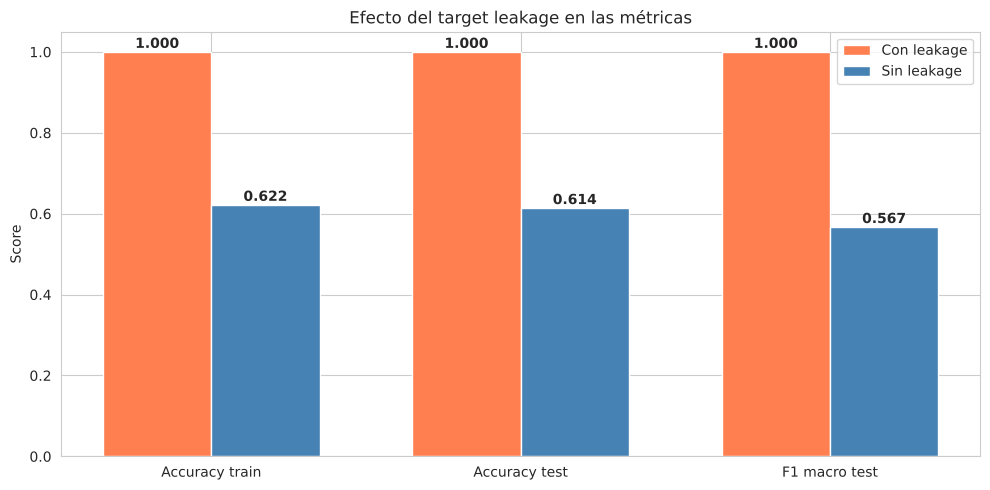


🔍 Diagnóstico:
  - Con leakage: accuracy cercana a perfect → el modelo copia la información del target.
  - Sin leakage: accuracy realista → el modelo aprende patrones genuinos.
  - Si en tu proyecto ves accuracy > 0.98, sospechá de leakage antes de celebrar.


In [5]:
comp = pd.DataFrame({
    'Con leakage':  [acc_train_leak, acc_test_leak, f1_test_leak],
    'Sin leakage':  [acc_train_ok,   acc_test_ok,   f1_test_ok]
}, index=['Accuracy train', 'Accuracy test', 'F1 macro test'])

print('Comparación lado a lado:')
print(comp.round(4))

fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(comp.index))
w = 0.35
ax.bar(x - w/2, comp['Con leakage'], w, label='Con leakage', color='coral')
ax.bar(x + w/2, comp['Sin leakage'], w, label='Sin leakage', color='steelblue')
ax.set_xticks(x)
ax.set_xticklabels(comp.index)
ax.set_ylabel('Score')
ax.set_title('Efecto del target leakage en las métricas')
ax.legend()
ax.set_ylim(0, 1.05)
for i, (v1, v2) in enumerate(zip(comp['Con leakage'], comp['Sin leakage'])):
    ax.text(i - w/2, v1 + 0.01, f'{v1:.3f}', ha='center', fontweight='bold')
    ax.text(i + w/2, v2 + 0.01, f'{v2:.3f}', ha='center', fontweight='bold')
plt.tight_layout()
plt.show()

print('\n🔍 Diagnóstico:')
print('  - Con leakage: accuracy cercana a perfect → el modelo copia la información del target.')
print('  - Sin leakage: accuracy realista → el modelo aprende patrones genuinos.')
print('  - Si en tu proyecto ves accuracy > 0.98, sospechá de leakage antes de celebrar.')

## 3. Experimento B — Train-Test Contamination

### El problema
Ocurre cuando el preprocesamiento (scaler, encoder, imputer) se ajusta **sobre todo el dataset**
antes del split. Las estadísticas de test se filtran al train.

### Cómo lo vamos a demostrar
Aplicamos `StandardScaler` dos veces:
1. **Forma incorrecta:** scaler fit sobre X completo, luego split.
2. **Forma correcta:** split primero, scaler fit solo sobre X_train.

In [6]:
from sklearn.linear_model import LogisticRegression

# Dataset pequeño donde el efecto se ve más claramente
muestra = df.sample(n=5000, random_state=42).copy()
X_num = muestra[['matricula_total', 'secciones_total']].fillna(muestra[['matricula_total','secciones_total']].median()).values
y_m   = muestra['nivel_repitencia'].values

# --- Forma INCORRECTA: scale sobre todo, luego split ---
scaler_wrong = StandardScaler()
X_scaled_all = scaler_wrong.fit_transform(X_num)  # fit sobre TODO
X_tr_w, X_te_w, y_tr_w, y_te_w = train_test_split(X_scaled_all, y_m, test_size=0.3, random_state=42, stratify=y_m)

model_w = LogisticRegression(max_iter=1000)
model_w.fit(X_tr_w, y_tr_w)
acc_wrong = accuracy_score(y_te_w, model_w.predict(X_te_w))

# --- Forma CORRECTA: split, luego scaler fit solo sobre train ---
X_tr_r, X_te_r, y_tr_r, y_te_r = train_test_split(X_num, y_m, test_size=0.3, random_state=42, stratify=y_m)
scaler_right = StandardScaler()
X_tr_r_sc = scaler_right.fit_transform(X_tr_r)      # fit SOLO sobre train
X_te_r_sc = scaler_right.transform(X_te_r)          # transform (no fit) sobre test

model_r = LogisticRegression(max_iter=1000)
model_r.fit(X_tr_r_sc, y_tr_r)
acc_right = accuracy_score(y_te_r, model_r.predict(X_te_r_sc))

print('=== Train-Test Contamination ===')
print(f'  Forma INCORRECTA (scaler sobre todo el dataset): Accuracy test = {acc_wrong:.4f}')
print(f'  Forma CORRECTA (scaler solo sobre train):       Accuracy test = {acc_right:.4f}')
print()
print(f'Diferencia: {abs(acc_wrong - acc_right):.4f}')
print()
print('En este caso particular la diferencia es pequeña porque StandardScaler con')
print('features bien distribuidas no cambia mucho. Pero con:')
print('  - Imputers (fillna con la media/mediana)')
print('  - Target encoders')
print('  - PCA')
print('el efecto puede ser catastrófico. La regla general: SIEMPRE split primero.')

=== Train-Test Contamination ===
  Forma INCORRECTA (scaler sobre todo el dataset): Accuracy test = 0.4820
  Forma CORRECTA (scaler solo sobre train):       Accuracy test = 0.4820

Diferencia: 0.0000

En este caso particular la diferencia es pequeña porque StandardScaler con
features bien distribuidas no cambia mucho. Pero con:
  - Imputers (fillna con la media/mediana)
  - Target encoders
  - PCA
el efecto puede ser catastrófico. La regla general: SIEMPRE split primero.


## 4. Experimento C — Leakage sutil con target encoding

Un caso de leakage más realista: usar la **media del target por provincia** como feature.
Si se calcula sobre todo el dataset (en vez de solo sobre train), filtra información del test.

In [7]:
# Convertir target a numérico para calcular medias
target_map = {'bajo': 0, 'medio': 1, 'alto': 2}
df['target_num'] = df['nivel_repitencia'].map(target_map)

# --- Leakage: target encoding calculado sobre TODO el dataset ---
media_por_provincia_leak = df.groupby('provincia')['target_num'].mean()
df['prov_encoded_leak'] = df['provincia'].map(media_por_provincia_leak)

features_leak_enc = ['matricula_total', 'secciones_total', 'prov_encoded_leak']
X_le = df[features_leak_enc].copy().fillna(df[features_leak_enc].median())
y_le = df['nivel_repitencia']

X_tr, X_te, y_tr, y_te = train_test_split(X_le, y_le, test_size=0.2, random_state=42, stratify=y_le)

m_leak = GradientBoostingClassifier(n_estimators=80, random_state=42)
m_leak.fit(X_tr, y_tr)
acc_le = accuracy_score(y_te, m_leak.predict(X_te))

# --- Sin leakage: target encoding calculado SOLO con train ---
X_tr2, X_te2, y_tr2, y_te2 = train_test_split(
    df[['matricula_total', 'secciones_total', 'provincia', 'target_num']].copy(),
    df['nivel_repitencia'], test_size=0.2, random_state=42, stratify=df['nivel_repitencia']
)

# Calcular encoding SOLO con train
media_train = X_tr2.groupby('provincia')['target_num'].mean()
X_tr2['prov_encoded'] = X_tr2['provincia'].map(media_train)
X_te2['prov_encoded'] = X_te2['provincia'].map(media_train)  # usar el map de train
X_te2['prov_encoded'] = X_te2['prov_encoded'].fillna(media_train.mean())  # fallback

X_tr2 = X_tr2[['matricula_total', 'secciones_total', 'prov_encoded']].fillna(X_tr2[['matricula_total','secciones_total','prov_encoded']].median())
X_te2 = X_te2[['matricula_total', 'secciones_total', 'prov_encoded']].fillna(X_tr2.median())

m_ok = GradientBoostingClassifier(n_estimators=80, random_state=42)
m_ok.fit(X_tr2, y_tr2)
acc_ok = accuracy_score(y_te2, m_ok.predict(X_te2))

print('=== Leakage por target encoding ===')
print(f'  Encoding calculado sobre TODO el dataset (leakage): Accuracy = {acc_le:.4f}')
print(f'  Encoding calculado SOLO con train (correcto):       Accuracy = {acc_ok:.4f}')
print()
print(f'Diferencia: {abs(acc_le - acc_ok):.4f}')
print()
print('Este es un tipo de leakage sutil y MUY común en la práctica.')
print('Herramientas como category_encoders tienen versiones CV-safe precisamente para evitar esto.')

=== Leakage por target encoding ===
  Encoding calculado sobre TODO el dataset (leakage): Accuracy = 0.5704
  Encoding calculado SOLO con train (correcto):       Accuracy = 0.5699

Diferencia: 0.0004

Este es un tipo de leakage sutil y MUY común en la práctica.
Herramientas como category_encoders tienen versiones CV-safe precisamente para evitar esto.


## 5. Cómo prevenirlo — usar Pipeline correctamente

In [8]:
# DEMO: Pipeline dentro de cross_val_score se ajusta automáticamente en cada fold solo con train
features_demo = ['matricula_total', 'secciones_total', 'provincia', 'sector', 'ambito']
num_d = ['matricula_total', 'secciones_total']
cat_d = ['provincia', 'sector', 'ambito']

X_demo = df[features_demo].copy()
y_demo = df['nivel_repitencia']

pre_demo = ColumnTransformer([
    ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())]), num_d),
    ('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')), ('enc', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), cat_d)
])
pipe_demo = Pipeline([('pre', pre_demo), ('model', GradientBoostingClassifier(n_estimators=80, random_state=42))])

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_val_score(pipe_demo, X_demo, y_demo, cv=skf, scoring='f1_macro', n_jobs=-1)

print('Cross-Validation con Pipeline (sin leakage posible):')
print(f'  F1 macro por fold: {np.round(scores, 4)}')
print(f'  F1 macro promedio: {scores.mean():.4f} ± {scores.std():.4f}')
print()
print('✅ Al usar Pipeline dentro de cross_val_score:')
print('  - El imputer se ajusta solo con los datos de train de cada fold')
print('  - El scaler se ajusta solo con los datos de train de cada fold')
print('  - El encoder aprende categorías solo del train de cada fold')
print('  - El modelo se entrena solo con train y se evalúa en test')
print('  → Imposible contaminar.')

Cross-Validation con Pipeline (sin leakage posible):
  F1 macro por fold: [0.5586 0.5636 0.5682 0.5652 0.555 ]
  F1 macro promedio: 0.5621 ± 0.0047

✅ Al usar Pipeline dentro de cross_val_score:
  - El imputer se ajusta solo con los datos de train de cada fold
  - El scaler se ajusta solo con los datos de train de cada fold
  - El encoder aprende categorías solo del train de cada fold
  - El modelo se entrena solo con train y se evalúa en test
  → Imposible contaminar.


## 6. Resumen — dónde está el leakage y por qué

| Tipo | Dónde aparece | Por qué |
|---|---|---|
| **Target leakage** | Una feature está causalmente derivada del target | El modelo puede "copiar" información del target |
| **Train-test contamination** | El preprocesador se ajusta antes del split | Estadísticas del test filtradas al train |
| **Target encoding leakage** | Medias del target calculadas sobre todo el dataset | Información global del target filtrada a cada fila |
| **Temporal leakage** | En series temporales, datos futuros en training | El modelo "ve el futuro" |
| **Group leakage** | Misma entidad en train y test | El modelo memoriza la entidad, no aprende el patrón |

### Checklist de detección
1. ¿Accuracy > 0.98 en un problema difícil? → Sospechar leakage.
2. ¿Gap train-test > 0.15? → Investigar.
3. ¿Alguna feature tiene correlación > 0.95 con el target? → Auditar esa feature.
4. ¿El preprocesamiento se hizo antes del split? → Corrección obligatoria.
5. ¿En producción la performance cae drásticamente? → Muy probable leakage no detectado.

### Regla de oro
> **Si una feature no está disponible en el momento de hacer la predicción en producción,
> no debe estar en el training set.**

En nuestro ejemplo: cuando el Ministerio consulta un establecimiento nuevo, no conoce
su `tasa_repitencia` — esa es justamente la variable que quiere predecir.
Incluirla como feature es imposible en producción, y por tanto tampoco debe usarse
durante el entrenamiento.